# Beach Human Detection — Corrected Faster R-CNN ResNet-50 FPN v2

**Purpose:** train the existing two-class Faster R-CNN project for 100 epochs on Roboflow YOLO-format annotations, save outputs to Google Drive, and generate evaluation graphs and detection visualizations.

- Dataset class IDs: `0 = Human on Land`, `1 = Human in Water`
- Faster R-CNN internal labels: `0 = background`, `1 = Human on Land`, `2 = Human in Water`
- `NUM_WORKERS = 0` to avoid the reported Colab `QueueFeederThread`/semaphore worker errors
- Neon-green bounding boxes and text, transparent label background, requested 100 px font
- Evaluation outputs: training loss, mAP@0.5, precision/recall/F1, per-class AP, PR curve, confidence curve, confusion matrix, sample predictions

**Important limitation:** this notebook has been checked for Python syntax and tested with synthetic annotations/predictions in this environment. The actual Roboflow dataset is not attached to this chat and needs your Roboflow credentials, so I cannot honestly claim I trained/evaluated on your private dataset here. Run the data-validation cells first in Colab; they deliberately stop if class order or folder layout is unexpected.

**API-key safety:** revoke the key previously pasted into chat and create a new Roboflow key. Enter it interactively when prompted; do not hard-code it in the notebook.

## 1. Runtime and setup
In Colab choose **Runtime → Change runtime type → GPU** (T4 if available). Run cells in order.

In [8]:
!pip -q install roboflow pyyaml seaborn pandas matplotlib tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 64.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.0 MB/s eta 0:00:00


In [9]:
import os, json, time, random, getpass, shutil, math
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from tqdm.auto import tqdm
from PIL import Image, ImageDraw, ImageFont
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:",torch.__version__,"| Device:",DEVICE)
if DEVICE.type != "cuda":
    print("WARNING: GPU not detected. Enable a Colab GPU before 100-epoch training.")

PyTorch: 2.11.0+cu130 | Device: cuda


## 2. Download the Roboflow dataset

In [13]:
from roboflow import Roboflow
ROBOFLOW_API_KEY = getpass.getpass("Enter your NEW Roboflow API key: ")
rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("image-analysis-project-rfnyq").project("vid_ds_bhd")
version = project.version(1)
dataset = version.download("yolov8")
DATASET_DIR = Path(dataset.location)
print("Downloaded dataset:", DATASET_DIR)
print("Top-level entries:", sorted(p.name for p in DATASET_DIR.iterdir()))

Enter your NEW Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to VID_DS_BHD-1 in yolov8:: 100%|██████████| 37/37 [00:00<00:00, 6431.65it/s]

Downloaded dataset: /content/VID_DS_BHD-1
Top-level entries: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'valid']


## 3. Validate dataset class order and split folders

In [14]:

import yaml
from pathlib import Path

yaml_candidates = list(DATASET_DIR.rglob("data.yaml"))

if not yaml_candidates:
    raise FileNotFoundError(f"No data.yaml found under {DATASET_DIR}")

yaml_path = yaml_candidates[0]

with open(yaml_path, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

raw_names = cfg.get("names")

if isinstance(raw_names, dict):
    names = [
        raw_names[k]
        for k in sorted(raw_names, key=lambda x: int(x))
    ]
elif isinstance(raw_names, list):
    names = raw_names
else:
    raise ValueError(f"Unexpected class names: {raw_names}")

if cfg.get("nc", len(names)) != 2 or len(names) != 2:
    raise ValueError(f"Expected two classes, found: {names}")

# Your required dataset ID mapping
CLASS_NAMES = ["Human on Land", "Human in Water"]

print("Roboflow names:", names)
print("Using required mapping:")
print("Class 0 =", CLASS_NAMES[0])
print("Class 1 =", CLASS_NAMES[1])

SPLITS = {
    split: DATASET_DIR / split
    for split in ["train", "valid", "test"]
}

for split, folder in SPLITS.items():
    image_folder = folder / "images"
    count = (
        sum(p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
            for p in image_folder.iterdir())
        if image_folder.exists()
        else 0
    )
    print(f"{split}: {count} images")

if not (SPLITS["train"] / "images").exists():
    raise FileNotFoundError("Training images folder not found.")

if not (SPLITS["valid"] / "images").exists():
    raise FileNotFoundError("Validation images folder not found.")


Roboflow names: ['0', '1']
Using required mapping:
Class 0 = Human on Land
Class 1 = Human in Water
train: 11 images
valid: 3 images
test: 2 images


## 4. Inspect YOLO annotation counts and check annotation files

In [15]:
IMG_EXTS={".jpg",".jpeg",".png",".bmp",".webp"}
annotation_counts=Counter()
empty_label_files=0
missing_label_files=[]
for split in ["train","valid","test"]:
    root=SPLITS[split]
    if not (root/"images").exists(): continue
    for ip in (root/"images").iterdir():
        if ip.suffix.lower() not in IMG_EXTS: continue
        lp=root/"labels"/(ip.stem+".txt")
        if not lp.exists():
            missing_label_files.append((split,ip.name))
            continue
        lines=[z.strip() for z in lp.read_text(encoding="utf-8").splitlines() if z.strip()]
        if not lines: empty_label_files+=1
        for line in lines:
            parts=line.split()
            if len(parts)<5: raise ValueError(f"Malformed annotation: {lp}: {line}")
            cid=int(float(parts[0]))
            if cid not in (0,1): raise ValueError(f"Unexpected class id {cid} in {lp}")
            vals=list(map(float,parts[1:5]))
            if not all(math.isfinite(v) for v in vals): raise ValueError(f"Non-finite box in {lp}")
            xc,yc,bw,bh=vals
            if not (0<=xc<=1 and 0<=yc<=1 and 0<bw<=1 and 0<bh<=1):
                raise ValueError(f"Out-of-range normalized YOLO box in {lp}: {vals}")
            annotation_counts[(split,cid)]+=1
print("Annotation counts:")
for split in ["train","valid","test"]:
    print(split, {CLASS_NAMES[c]:annotation_counts[(split,c)] for c in (0,1)})
print("Empty label files:",empty_label_files)
print("Images missing a label file:",len(missing_label_files))
if missing_label_files[:10]: print("First missing labels:",missing_label_files[:10])
if annotation_counts[("train",0)]==0 or annotation_counts[("train",1)]==0:
    raise ValueError("At least one class has zero training annotations. Check class IDs and labels before training.")

Annotation counts:
train {'Human on Land': 150, 'Human in Water': 440}
valid {'Human on Land': 45, 'Human in Water': 117}
test {'Human on Land': 32, 'Human in Water': 75}
Empty label files: 0
Images missing a label file: 0


## 5. Dataset loader (YOLO IDs → Faster R-CNN internal labels)

In [16]:
class RoboflowDetectionDataset(Dataset):
    def __init__(self, split_dir):
        self.root=Path(split_dir)
        self.img_dir=self.root/"images"; self.lab_dir=self.root/"labels"
        self.images=sorted(p for p in self.img_dir.iterdir() if p.suffix.lower() in IMG_EXTS)
        if not self.images: raise RuntimeError(f"No images in {self.img_dir}")
    def __len__(self): return len(self.images)
    def __getitem__(self,idx):
        path=self.images[idx]
        image=Image.open(path).convert("RGB")
        w,h=image.size
        x=TF.to_tensor(image)
        boxes=[]; labels=[]
        lab=self.lab_dir/(path.stem+".txt")
        if lab.exists():
            for line in lab.read_text(encoding="utf-8").splitlines():
                parts=line.split()
                if len(parts)<5: continue
                cls=int(float(parts[0])); xc,yc,bw,bh=map(float,parts[1:5])
                if cls not in (0,1): continue
                x1=max(0.0,(xc-bw/2)*w); y1=max(0.0,(yc-bh/2)*h)
                x2=min(float(w),(xc+bw/2)*w); y2=min(float(h),(yc+bh/2)*h)
                if x2>x1 and y2>y1:
                    boxes.append([x1,y1,x2,y2])
                    labels.append(cls+1)  # land 0->internal 1; water 1->internal 2
        target={
            "boxes":torch.as_tensor(boxes,dtype=torch.float32).reshape(-1,4),
            "labels":torch.as_tensor(labels,dtype=torch.int64),
            "image_id":torch.tensor([idx]),
            "area":torch.as_tensor([(b[2]-b[0])*(b[3]-b[1]) for b in boxes],dtype=torch.float32),
            "iscrowd":torch.zeros(len(boxes),dtype=torch.int64)
        }
        return x,target

def collate_fn(batch): return tuple(zip(*batch))
train_ds=RoboflowDetectionDataset(SPLITS["train"])
valid_ds=RoboflowDetectionDataset(SPLITS["valid"])
test_ds=RoboflowDetectionDataset(SPLITS["test"]) if (SPLITS["test"]/"images").exists() else None
BATCH_SIZE=4
NUM_WORKERS=0  # workaround for Colab QueueFeederThread / bad file descriptor / semaphore errors
def make_loader(ds,shuffle):
    return DataLoader(ds,batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=NUM_WORKERS,
                      collate_fn=collate_fn,pin_memory=(DEVICE.type=="cuda"))
train_loader=make_loader(train_ds,True)
valid_loader=make_loader(valid_ds,False)
test_loader=make_loader(test_ds,False) if test_ds is not None else None
print("Images: train",len(train_ds),"valid",len(valid_ds),"test",len(test_ds) if test_ds else 0)

Images: train 11 valid 3 test 2


## 6. Visual audit of ground-truth boxes

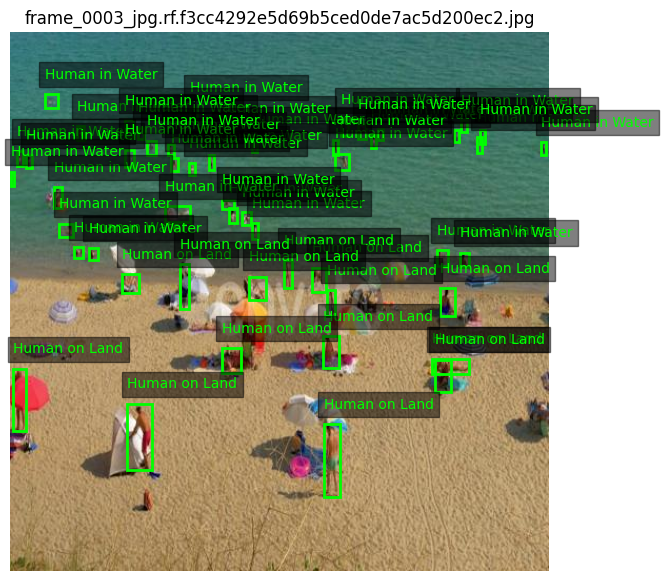

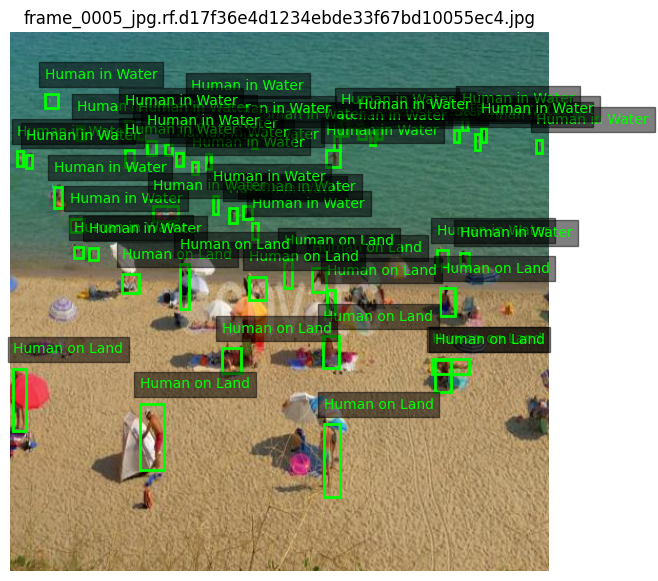

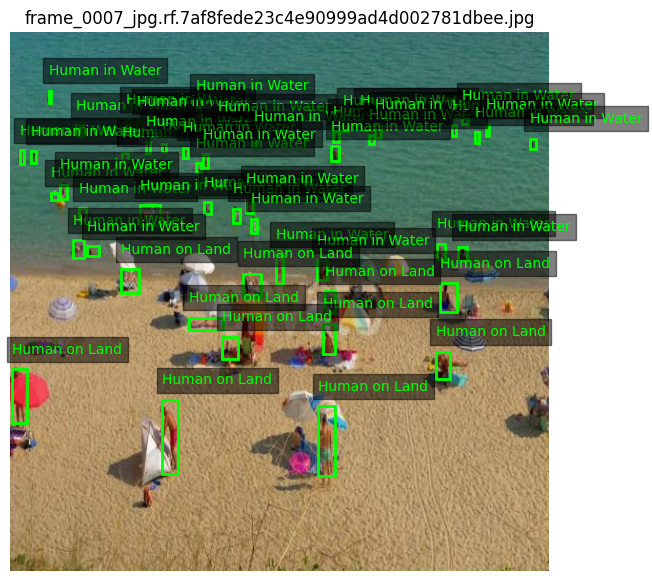

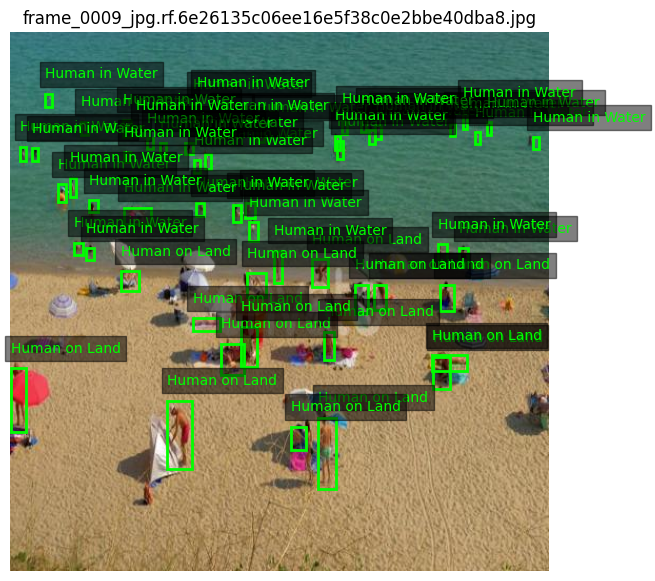

In [17]:
def show_ground_truth(ds,idx):
    image,target=ds[idx]
    fig,ax=plt.subplots(figsize=(12,7)); ax.imshow(image.permute(1,2,0))
    for box,internal_label in zip(target["boxes"].numpy(),target["labels"].numpy()):
        x1,y1,x2,y2=box
        ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor="lime",linewidth=2))
        ax.text(x1,max(0,y1-15),CLASS_NAMES[int(internal_label)-1],color="lime",
                bbox=dict(facecolor="black",alpha=.5))
    ax.set_title(train_ds.images[idx].name); ax.axis("off"); plt.show()
for i in range(min(4,len(train_ds))): show_ground_truth(train_ds,i)

## 7. Model, optimizer, and output directory

In [19]:
model=fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT)
in_features=model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor=FastRCNNPredictor(in_features,3) # background + 2 classes
model.to(DEVICE)
NUM_EPOCHS=100
optimizer=torch.optim.SGD([p for p in model.parameters() if p.requires_grad],
                          lr=0.005,momentum=0.9,weight_decay=0.0005)
scheduler=torch.optim.lr_scheduler.StepLR(optimizer,step_size=4,gamma=0.1)
from google.colab import drive
drive.mount("/content/drive")
OUT=Path("/content/drive/MyDrive/beach_human_detection_corrected")
OUT.mkdir(parents=True,exist_ok=True)
BEST_PATH=OUT/"fasterrcnn_best.pth"
LAST_PATH=OUT/"fasterrcnn_last.pth"
HISTORY_PATH=OUT/"training_history.csv"
print("Saving outputs to",OUT)

Mounted at /content/drive
Saving outputs to /content/drive/MyDrive/beach_human_detection_corrected


## 8. Validation metrics (IoU matching at 0.5; class AP from ranked detections)

In [20]:
def box_iou_one(box,boxes):
    if len(boxes)==0: return np.zeros(0,dtype=float)
    xx1=np.maximum(box[0],boxes[:,0]); yy1=np.maximum(box[1],boxes[:,1])
    xx2=np.minimum(box[2],boxes[:,2]); yy2=np.minimum(box[3],boxes[:,3])
    inter=np.maximum(0,xx2-xx1)*np.maximum(0,yy2-yy1)
    area1=max(0,box[2]-box[0])*max(0,box[3]-box[1])
    area2=np.maximum(0,boxes[:,2]-boxes[:,0])*np.maximum(0,boxes[:,3]-boxes[:,1])
    return inter/np.maximum(area1+area2-inter,1e-9)

@torch.no_grad()
def collect_records(model,loader):
    model.eval(); records=[]
    for images,targets in tqdm(loader,leave=False):
        outputs=model([im.to(DEVICE) for im in images])
        for image,target,out in zip(images,targets,outputs):
            records.append({"image":image.cpu(),"gt_boxes":target["boxes"].numpy(),
                "gt_labels":target["labels"].numpy(),"pred_boxes":out["boxes"].cpu().numpy(),
                "pred_labels":out["labels"].cpu().numpy(),"scores":out["scores"].cpu().numpy()})
    return records

def evaluate(records,iou_thr=0.5,conf_thr=0.5):
    per_class={}; all_tp=all_fp=all_fn=0
    for cls,name in enumerate(CLASS_NAMES,1):
        gt_boxes=[r["gt_boxes"][r["gt_labels"]==cls] for r in records]
        matched=[np.zeros(len(g),dtype=bool) for g in gt_boxes]
        n_gt=sum(map(len,gt_boxes)); detections=[]
        for image_idx,r in enumerate(records):
            mask=(r["pred_labels"]==cls)&(r["scores"]>=0.001)
            detections.extend((float(s),image_idx,b) for b,s in zip(r["pred_boxes"][mask],r["scores"][mask]))
        detections.sort(key=lambda z:z[0],reverse=True)
        tps=[];fps=[]
        for score,image_idx,box in detections:
            overlaps=box_iou_one(box,gt_boxes[image_idx])
            if len(overlaps):
                overlaps[matched[image_idx]]=-1
                j=int(np.argmax(overlaps))
                if overlaps[j]>=iou_thr:
                    tps.append(1);fps.append(0);matched[image_idx][j]=True
                else: tps.append(0);fps.append(1)
            else: tps.append(0);fps.append(1)
        if tps and n_gt:
            ctp=np.cumsum(tps); cfp=np.cumsum(fps)
            recall_curve=ctp/n_gt; precision_curve=ctp/np.maximum(ctp+cfp,1)
            mr=np.r_[0,recall_curve,1]; mp=np.r_[0,precision_curve,0]
            for j in range(len(mp)-2,-1,-1): mp[j]=max(mp[j],mp[j+1])
            inds=np.where(mr[1:]!=mr[:-1])[0]
            ap=float(np.sum((mr[inds+1]-mr[inds])*mp[inds+1]))
        else: ap=0.0
        tp=fp=fn=0
        for r in records:
            g=r["gt_boxes"][r["gt_labels"]==cls]
            mask=(r["pred_labels"]==cls)&(r["scores"]>=conf_thr)
            pboxes=r["pred_boxes"][mask]
            used=np.zeros(len(g),dtype=bool)
            for box in pboxes:
                overlaps=box_iou_one(box,g)
                if len(overlaps):
                    overlaps[used]=-1;j=int(np.argmax(overlaps))
                    if overlaps[j]>=iou_thr: tp+=1;used[j]=True
                    else: fp+=1
                else: fp+=1
            fn+=int((~used).sum())
        precision=tp/max(tp+fp,1); recall=tp/max(tp+fn,1)
        f1=2*precision*recall/max(precision+recall,1e-12)
        per_class[name]={"AP":ap,"precision":precision,"recall":recall,"F1":f1,"ground_truth":n_gt}
        all_tp+=tp;all_fp+=fp;all_fn+=fn
    p=all_tp/max(all_tp+all_fp,1);r=all_tp/max(all_tp+all_fn,1)
    return {"map50":float(np.mean([v["AP"] for v in per_class.values()])),
            "precision":p,"recall":r,"f1":2*p*r/max(p+r,1e-12),"per_class":per_class}

## 9. Train for 100 epochs (checkpoint every epoch)

In [21]:
def train_one_epoch():
    model.train(); total_loss=0.0; seen=0
    for images,targets in tqdm(train_loader,leave=False):
        images=[im.to(DEVICE) for im in images]
        targets=[{k:v.to(DEVICE) for k,v in t.items()} for t in targets]
        loss_dict=model(images,targets); loss=sum(loss_dict.values())
        if not torch.isfinite(loss): raise RuntimeError(f"Non-finite training loss: {loss.item()}")
        optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
        total_loss+=float(loss.item())*len(images); seen+=len(images)
    return total_loss/max(seen,1)

history=[]; best_map=-1.0; start=time.time()
for epoch in range(1,NUM_EPOCHS+1):
    epoch_start=time.time()
    train_loss=train_one_epoch()
    scheduler.step()
    val_records=collect_records(model,valid_loader)
    val=evaluate(val_records,iou_thr=0.5,conf_thr=0.5)
    row={"epoch":epoch,"train_loss":train_loss,"val_map50":val["map50"],
         "val_precision":val["precision"],"val_recall":val["recall"],"val_f1":val["f1"],
         "learning_rate":optimizer.param_groups[0]["lr"],"seconds":time.time()-epoch_start}
    history.append(row);pd.DataFrame(history).to_csv(HISTORY_PATH,index=False)
    state={"epoch":epoch,"model_state_dict":model.state_dict(),
           "optimizer_state_dict":optimizer.state_dict(),"class_names":CLASS_NAMES,"history":history}
    torch.save(state,LAST_PATH)
    if val["map50"]>best_map:
        best_map=val["map50"];torch.save(state,BEST_PATH)
    print(f"Epoch {epoch:03d}/{NUM_EPOCHS} | loss={train_loss:.4f} | "
          f"mAP50={val['map50']:.4f} | P={val['precision']:.4f} | "
          f"R={val['recall']:.4f} | F1={val['f1']:.4f} | "
          f"{row['seconds']:.1f}s")
print(f"Training completed in {(time.time()-start)/60:.1f} minutes")

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 001/100 | loss=2.0818 | mAP50=0.3244 | P=0.0000 | R=0.0000 | F1=0.0000 | 8.4s


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

...

  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 099/100 | loss=1.0673 | mAP50=0.4816 | P=0.5605 | R=0.5432 | F1=0.5517 | 6.0s


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Epoch 100/100 | loss=1.0934 | mAP50=0.4823 | P=0.5641 | R=0.5432 | F1=0.5535 | 6.0s
Training completed in 15.1 minutes


## 10. Training graphs

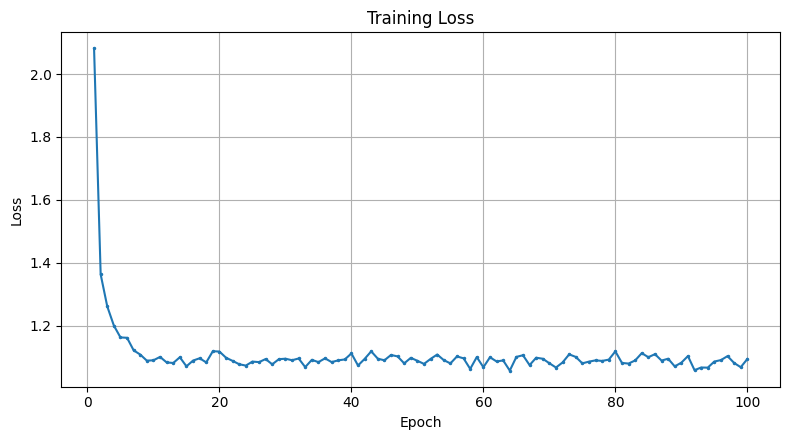

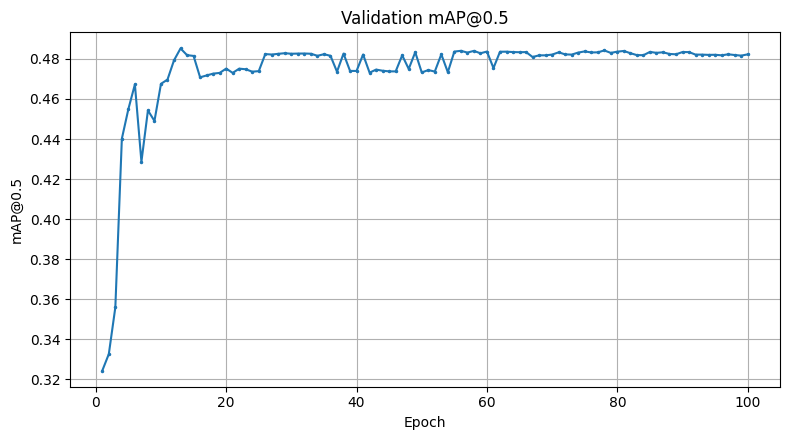

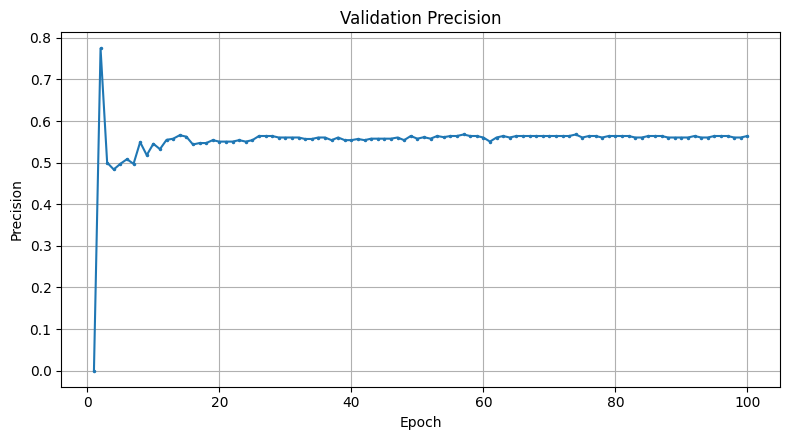

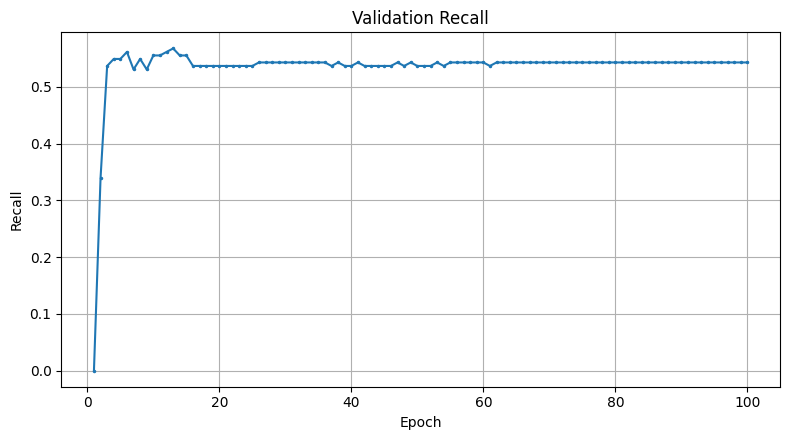

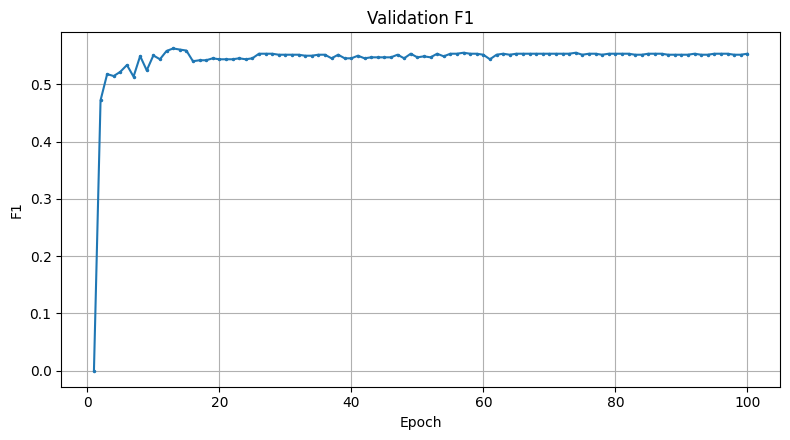

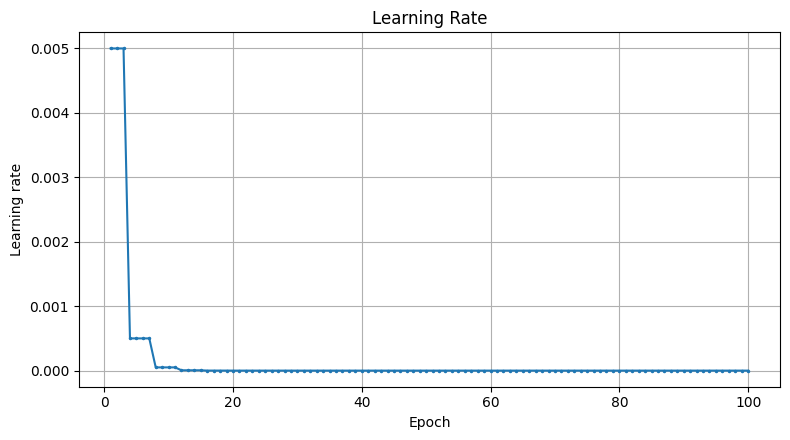

,epoch,train_loss,val_map50,val_precision,val_recall,val_f1,learning_rate,seconds
95,96,1.089922,0.481796,0.564103,0.54321,0.553459,5.000000e-27,5.977890
96,97,1.102631,0.482308,0.564103,0.54321,0.553459,5.000000e-27,6.015085
97,98,1.080698,0.481946,0.560510,0.54321,0.551724,5.000000e-27,6.032514
98,99,1.067336,0.481650,0.560510,0.54321,0.551724,5.000000e-27,6.040141
99,100,1.093354,0.482279,0.564103,0.54321,0.553459,5.000000e-28,6.014785


In [22]:
hist=pd.read_csv(HISTORY_PATH)
def save_plot(filename):
    plt.tight_layout();plt.savefig(OUT/filename,dpi=180,bbox_inches="tight");plt.show()
for col,title,ylabel,filename in [
    ("train_loss","Training Loss","Loss","training_loss.png"),
    ("val_map50","Validation mAP@0.5","mAP@0.5","validation_map50.png"),
    ("val_precision","Validation Precision","Precision","validation_precision.png"),
    ("val_recall","Validation Recall","Recall","validation_recall.png"),
    ("val_f1","Validation F1","F1","validation_f1.png"),
    ("learning_rate","Learning Rate","Learning rate","learning_rate.png")]:
    plt.figure(figsize=(8,4.5));plt.plot(hist.epoch,hist[col],marker=".",markersize=3)
    plt.title(title);plt.xlabel("Epoch");plt.ylabel(ylabel);plt.grid(True);save_plot(filename)
display(hist.tail())

## 11. Load best checkpoint and evaluate held-out test split

In [23]:
ckpt=torch.load(BEST_PATH,map_location=DEVICE)
model.load_state_dict(ckpt["model_state_dict"]);model.to(DEVICE).eval()
eval_loader=test_loader if test_loader is not None else valid_loader
eval_split="test" if test_loader is not None else "validation (test split not present)"
records=collect_records(model,eval_loader)
metrics=evaluate(records,0.5,0.5)
aps_by_iou={round(float(thr),2):evaluate(records,float(thr),0.5)["map50"] for thr in np.arange(0.5,0.951,0.05)}
map50_95=float(np.mean(list(aps_by_iou.values())))
print("Evaluation split:",eval_split)
print(f"mAP@0.5 (custom evaluator): {metrics['map50']:.4f}")
print(f"mAP@0.5:0.95 (custom average): {map50_95:.4f}")
print(f"Precision={metrics['precision']:.4f} Recall={metrics['recall']:.4f} F1={metrics['f1']:.4f}")
display(pd.DataFrame(metrics["per_class"]).T)
summary={"evaluation_split":eval_split,"epochs":NUM_EPOCHS,"map50_custom":metrics["map50"],
         "map50_95_custom":map50_95,"precision":metrics["precision"],"recall":metrics["recall"],
         "f1":metrics["f1"],"per_class":metrics["per_class"],"ap_by_iou":aps_by_iou}
(OUT/"evaluation_summary.json").write_text(json.dumps(summary,indent=2))

  0%|          | 0/1 [00:00<?, ?it/s]

Evaluation split: test
mAP@0.5 (custom evaluator): 0.3666
mAP@0.5:0.95 (custom average): 0.1096
Precision=0.4595 Recall=0.4766 F1=0.4679


,AP,precision,recall,F1,ground_truth
Human on Land,0.234205,0.000000,0.00,0.000000,32.0
Human in Water,0.499089,0.459459,0.68,0.548387,75.0


888

## 12. Detection confusion matrix (background row/column included)

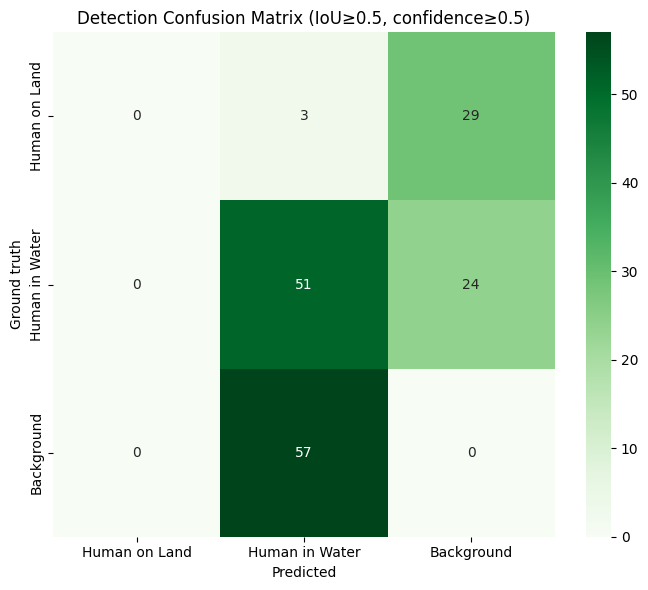

In [24]:
def detection_confusion(records,conf_thr=0.5,iou_thr=0.5):
    ncls=len(CLASS_NAMES); bg=ncls
    cm=np.zeros((ncls+1,ncls+1),dtype=int)
    for r in records:
        gt_boxes=r["gt_boxes"];gt_labels=r["gt_labels"]
        keep=r["scores"]>=conf_thr
        pb=r["pred_boxes"][keep];pl=r["pred_labels"][keep];ps=r["scores"][keep]
        order=np.argsort(-ps);pb,pl=pb[order],pl[order]
        gt_used=np.zeros(len(gt_boxes),dtype=bool);pred_used=np.zeros(len(pb),dtype=bool)
        for i,box in enumerate(pb):
            if len(gt_boxes)==0: break
            overlaps=box_iou_one(box,gt_boxes);overlaps[gt_used]=-1;j=int(np.argmax(overlaps))
            if overlaps[j]>=iou_thr:
                cm[int(gt_labels[j])-1,int(pl[i])-1]+=1
                gt_used[j]=True;pred_used[i]=True
        for j in range(len(gt_boxes)):
            if not gt_used[j]: cm[int(gt_labels[j])-1,bg]+=1
        for i in range(len(pb)):
            if not pred_used[i]: cm[bg,int(pl[i])-1]+=1
    labels=CLASS_NAMES+["Background"]
    return cm,labels
cm, cm_labels = detection_confusion(records)
plt.figure(figsize=(7,6));sns.heatmap(cm,annot=True,fmt="d",cmap="Greens",xticklabels=cm_labels,yticklabels=cm_labels)
plt.xlabel("Predicted");plt.ylabel("Ground truth");plt.title("Detection Confusion Matrix (IoU≥0.5, confidence≥0.5)")
save_plot("confusion_matrix.png")
pd.DataFrame(cm,index=cm_labels,columns=cm_labels).to_csv(OUT/"confusion_matrix.csv")

## 13. Precision–recall curve, confidence curves, and per-class AP

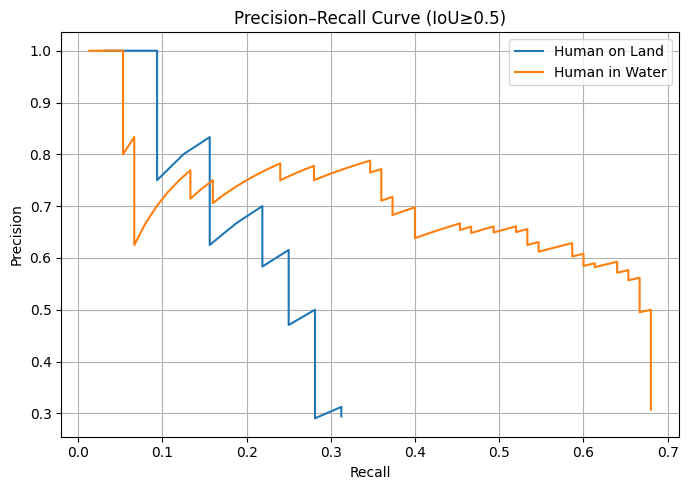

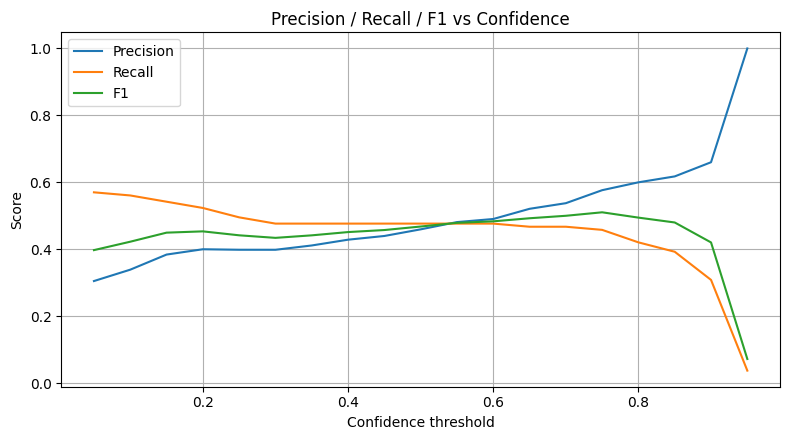

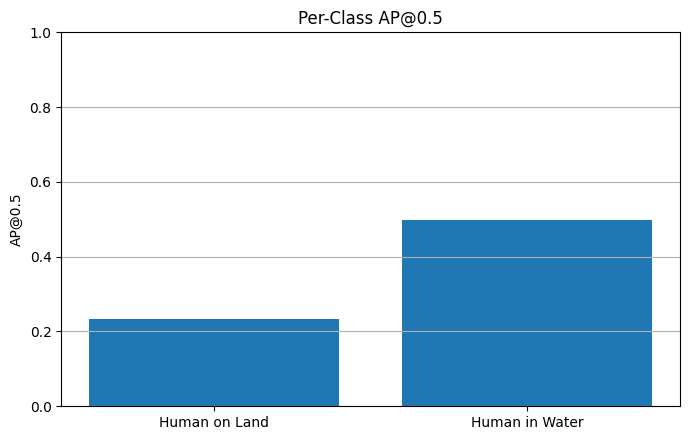

In [25]:
plt.figure(figsize=(7,5))
for cls,name in enumerate(CLASS_NAMES,1):
    gts=[r["gt_boxes"][r["gt_labels"]==cls] for r in records]
    matched=[np.zeros(len(g),dtype=bool) for g in gts]
    n_gt=sum(map(len,gts));dets=[]
    for k,r in enumerate(records):
        mask=(r["pred_labels"]==cls)&(r["scores"]>=0.001)
        dets.extend((float(s),k,b) for b,s in zip(r["pred_boxes"][mask],r["scores"][mask]))
    dets.sort(key=lambda z:z[0],reverse=True);tp=[];fp=[]
    for score,k,b in dets:
        ov=box_iou_one(b,gts[k])
        if len(ov):
            ov[matched[k]]=-1;j=int(np.argmax(ov))
            if ov[j]>=0.5:tp.append(1);fp.append(0);matched[k][j]=True
            else:tp.append(0);fp.append(1)
        else:tp.append(0);fp.append(1)
    if tp and n_gt:
        ct=np.cumsum(tp);cf=np.cumsum(fp)
        plt.plot(ct/n_gt,ct/np.maximum(ct+cf,1),label=name)
plt.xlabel("Recall");plt.ylabel("Precision");plt.title("Precision–Recall Curve (IoU≥0.5)")
plt.grid(True);plt.legend();save_plot("precision_recall_curve.png")

thresholds=np.linspace(0.05,0.95,19);ps=[];rs=[];fs=[]
for threshold in thresholds:
    m=evaluate(records,0.5,float(threshold));ps.append(m["precision"]);rs.append(m["recall"]);fs.append(m["f1"])
plt.figure(figsize=(8,4.5));plt.plot(thresholds,ps,label="Precision");plt.plot(thresholds,rs,label="Recall");plt.plot(thresholds,fs,label="F1")
plt.xlabel("Confidence threshold");plt.ylabel("Score");plt.title("Precision / Recall / F1 vs Confidence")
plt.grid(True);plt.legend();save_plot("confidence_curves.png")
per=pd.DataFrame(metrics["per_class"]).T
plt.figure(figsize=(7,4.5));plt.bar(per.index,per["AP"]);plt.ylim(0,1);plt.ylabel("AP@0.5");plt.title("Per-Class AP@0.5")
plt.grid(axis="y");save_plot("per_class_ap.png")

## 14. Prediction visualization: neon green, transparent background, 100 px

In [26]:

from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
import subprocess

# Find an installed TrueType font in Google Colab
FONT_PATH = None

try:
    result = subprocess.run(
        ["fc-match", "-f", "%{file}", "DejaVu Sans"],
        capture_output=True,
        text=True,
        check=True
    )
    candidate = result.stdout.strip()

    if candidate and Path(candidate).is_file():
        FONT_PATH = candidate
except Exception:
    pass

# Search common font directories if fc-match did not work
if FONT_PATH is None:
    search_dirs = [
        Path("/usr/share/fonts"),
        Path("/usr/local/share/fonts"),
        Path("/usr/local/lib/python3.11/site-packages")
    ]

    for folder in search_dirs:
        if folder.exists():
            matches = list(folder.rglob("*.ttf"))
            if matches:
                FONT_PATH = str(matches[0])
                break

if FONT_PATH is None:
    raise FileNotFoundError(
        "No TrueType font found. Install a font and rerun this cell."
    )

FONT = ImageFont.truetype(FONT_PATH, 100)

print("Font loaded:", FONT_PATH)
print("Font size: 100 px")


Font loaded: /usr/share/fonts/truetype/liberation/LiberationMono-Regular.ttf
Font size: 100 px


## 15. Save annotated images and package outputs

In [27]:

from PIL import Image, ImageDraw, ImageFont
from pathlib import Path

# Find an available TrueType font
import subprocess

result = subprocess.run(
    ["fc-match", "-f", "%{file}", "DejaVu Sans"],
    capture_output=True,
    text=True
)
FONT_PATH = result.stdout.strip()

if not FONT_PATH or not Path(FONT_PATH).is_file():
    raise FileNotFoundError(
        "No TrueType font found. Install fonts before continuing."
    )

FONT = ImageFont.truetype(FONT_PATH, 100)

# Dataset class IDs: 0 = Land, 1 = Water
CLASS_NAMES = ["Human on Land", "Human in Water"]

def draw_neon_predictions(
    image,
    boxes,
    internal_labels,
    scores,
    confidence=0.35
):
    image = image.convert("RGB").copy()
    draw = ImageDraw.Draw(image)
    neon_green = (57, 255, 20)

    for box, label, score in zip(boxes, internal_labels, scores):
        if float(score) < confidence:
            continue

        # Faster R-CNN: 0 is background, 1 and 2 are object classes
        label = int(label)
        if label not in (1, 2):
            continue

        x1, y1, x2, y2 = map(int, box)
        class_id = label - 1

        text = (
            f"{class_id} {CLASS_NAMES[class_id]} "
            f"{float(score):.2f}"
        )

        draw.rectangle(
            (x1, y1, x2, y2),
            outline=neon_green,
            width=4
        )

        # Transparent background; 100 px neon-green text
        draw.text(
            (x1, max(0, y1 - 105)),
            text,
            font=FONT,
            fill=neon_green,
            stroke_width=1,
            stroke_fill=(0, 0, 0)
        )

    return image

print("Prediction drawing function defined successfully.")
print("Font size: 100 px")


Prediction drawing function defined successfully.
Font size: 100 px


Found 2 predicted images.
prediction_frame_0002_jpg.rf.b4699d06d5b5e60bcbebf56cc78a4473.jpg


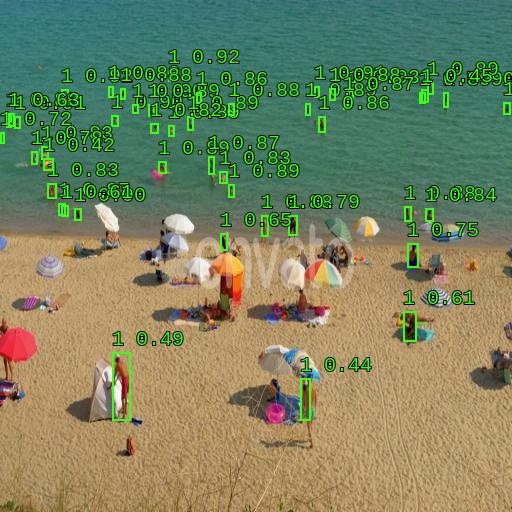

prediction_frame_0004_jpg.rf.2e40c6030b4a6cd5dd70ae6301ae5107.jpg


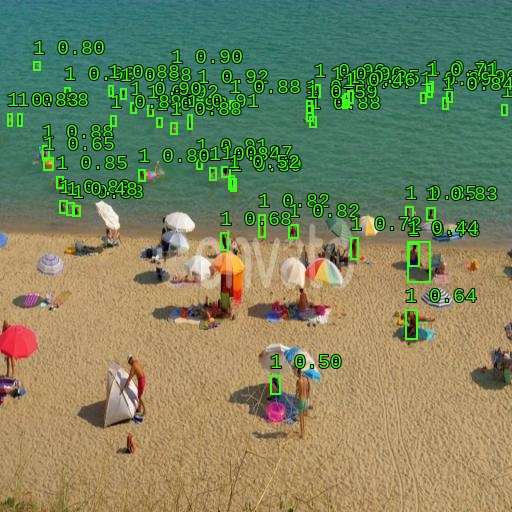

In [28]:

from pathlib import Path
from PIL import Image
from IPython.display import display

pred_dir = OUT / "sample_predictions"

if pred_dir.exists():
    images = sorted(pred_dir.glob("prediction_*.jpg"))
    print(f"Found {len(images)} predicted images.")

    for path in images:
        print(path.name)
        display(Image.open(path))
else:
    print("Prediction folder not found. Run the prediction-saving cell first.")


In [29]:
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from pathlib import Path

OUT = Path("/content/drive/MyDrive/beach_human_detection_corrected")
MODEL_PATH = OUT / "fasterrcnn_best.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = fasterrcnn_resnet50_fpn_v2(
    weights=None,
    weights_backbone=None,
    num_classes=3  # background + 2 human classes
)

checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=False)

# Support either a raw state dictionary or a checkpoint dictionary
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

model.load_state_dict(state_dict)
model.to(device)
model.eval()

print("Model loaded successfully on", device)

Model loaded successfully on cuda


Dataset class names: ['0', '1']
Training annotation counts: {'0': 150, '1': 440}
Inference device: cuda

Processed 2 images.
Saved to: /content/drive/MyDrive/beach_human_detection_corrected/sample_predictions
Confidence threshold: 0.4
NMS IoU threshold: 0.4
prediction_frame_0002_jpg.rf.b4699d06d5b5e60bcbebf56cc78a4473.jpg


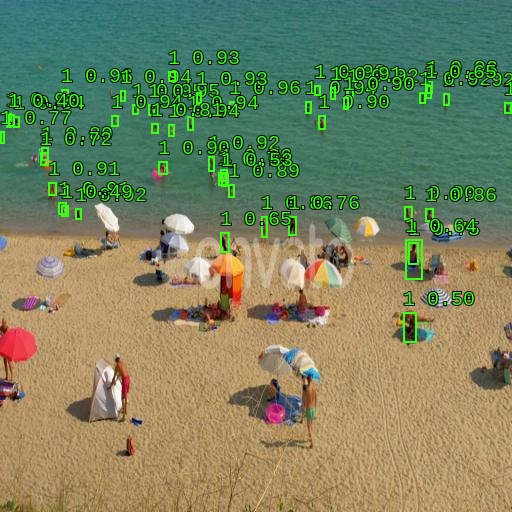

prediction_frame_0004_jpg.rf.2e40c6030b4a6cd5dd70ae6301ae5107.jpg


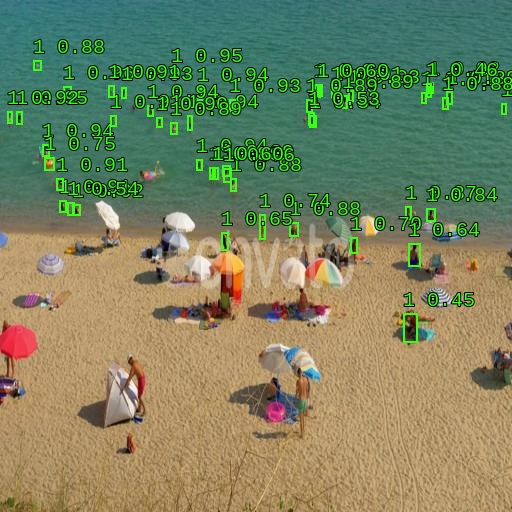

In [30]:

# ============================================================
# BEACH HUMAN DETECTION - COMPLETE PREDICTION CELL
# 0 = Human on Land
# 1 = Human in Water
# ============================================================

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from torchvision.transforms.functional import to_tensor
from torchvision.ops import nms
from IPython.display import display
from collections import Counter
import torch
import yaml
import subprocess

# -------------------- PATHS --------------------

OUT = Path("/content/drive/MyDrive/beach_human_detection_corrected")
DATA_DIR = Path("/content/VID_DS_BHD-1")
TEST_DIR = DATA_DIR / "test" / "images"
LABEL_DIR = DATA_DIR / "train" / "labels"
SAVE_DIR = OUT / "sample_predictions"

SAVE_DIR.mkdir(parents=True, exist_ok=True)

# -------------------- SETTINGS --------------------

CONF_THRESHOLD = 0.40
NMS_THRESHOLD = 0.40
FONT_SIZE = 20
BOX_WIDTH = 2
NEON_GREEN = (57, 255, 20)

# -------------------- CHECK CLASS MAPPING --------------------

yaml_path = DATA_DIR / "data.yaml"

if yaml_path.exists():
    with open(yaml_path, "r") as f:
        data_cfg = yaml.safe_load(f)

    print("Dataset class names:", data_cfg.get("names"))
else:
    print("Warning: data.yaml not found.")

# Count annotations for diagnostic purposes
counts = Counter()

if LABEL_DIR.exists():
    for label_file in LABEL_DIR.glob("*.txt"):
        for line in label_file.read_text().splitlines():
            parts = line.split()
            if parts:
                counts[parts[0]] += 1

print("Training annotation counts:", dict(counts))

# -------------------- CHECK MODEL --------------------

if "model" not in globals():
    raise RuntimeError(
        "Trained model is not loaded. Run the model-loading cell first."
    )

if "device" not in globals():
    device = next(model.parameters()).device

model.eval()
print("Inference device:", device)

# -------------------- LOAD FONT --------------------

font_result = subprocess.run(
    ["fc-match", "-f", "%{file}", "DejaVu Sans"],
    capture_output=True,
    text=True
)

font_path = font_result.stdout.strip()

if not font_path or not Path(font_path).is_file():
    raise FileNotFoundError(
        "Font not found. Run: !apt-get install -y fonts-dejavu-core"
    )

FONT = ImageFont.truetype(font_path, FONT_SIZE)

# -------------------- FIND TEST IMAGES --------------------

if not TEST_DIR.exists():
    raise FileNotFoundError(f"Test directory not found: {TEST_DIR}")

image_paths = sorted(
    p for p in TEST_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

if not image_paths:
    raise FileNotFoundError(f"No test images found in {TEST_DIR}")

# Clear previous predictions to avoid mixing old results
for old_file in SAVE_DIR.glob("prediction_*"):
    if old_file.is_file():
        old_file.unlink()

# -------------------- PREDICT --------------------

saved_paths = []

with torch.inference_mode():
    for image_path in image_paths:
        image = Image.open(image_path).convert("RGB")
        image_tensor = to_tensor(image).to(device)

        prediction = model([image_tensor])[0]

        boxes = prediction["boxes"].detach().cpu()
        labels = prediction["labels"].detach().cpu()
        scores = prediction["scores"].detach().cpu()

        # Confidence filtering
        confidence_mask = scores >= CONF_THRESHOLD

        boxes = boxes[confidence_mask]
        labels = labels[confidence_mask]
        scores = scores[confidence_mask]

        # Class-wise non-maximum suppression
        kept_indices = []

        for internal_label in (1, 2):
            class_indices = torch.where(labels == internal_label)[0]

            if len(class_indices) == 0:
                continue

            class_keep = nms(
                boxes[class_indices],
                scores[class_indices],
                NMS_THRESHOLD
            )

            kept_indices.extend(
                class_indices[class_keep].tolist()
            )

        draw = ImageDraw.Draw(image)

        for idx in kept_indices:
            internal_label = int(labels[idx])
            score = float(scores[idx])

            # Faster R-CNN internal labels:
            # 0 = background, 1 = dataset class 0, 2 = dataset class 1
            class_id = internal_label - 1

            if class_id not in (0, 1):
                continue

            x1, y1, x2, y2 = map(int, boxes[idx].tolist())

            # Clamp coordinates to image boundaries
            x1 = max(0, min(x1, image.width - 1))
            x2 = max(0, min(x2, image.width - 1))
            y1 = max(0, min(y1, image.height - 1))
            y2 = max(0, min(y2, image.height - 1))

            if x2 <= x1 or y2 <= y1:
                continue

            # Draw neon-green bounding box
            draw.rectangle(
                (x1, y1, x2, y2),
                outline=NEON_GREEN,
                width=BOX_WIDTH
            )

            # Show ID and confidence only
            label_text = f"{class_id} {score:.2f}"

            text_y = y1 - FONT_SIZE - 4
            if text_y < 0:
                text_y = min(y1 + 2, image.height - FONT_SIZE)

            # No filled background behind the text
            draw.text(
                (x1, max(0, text_y)),
                label_text,
                font=FONT,
                fill=NEON_GREEN,
                stroke_width=1,
                stroke_fill=(0, 0, 0)
            )

        output_path = SAVE_DIR / f"prediction_{image_path.stem}.jpg"
        image.save(output_path, quality=95)
        saved_paths.append(output_path)

# -------------------- DISPLAY RESULTS --------------------

print(f"\nProcessed {len(saved_paths)} images.")
print(f"Saved to: {SAVE_DIR}")
print(f"Confidence threshold: {CONF_THRESHOLD}")
print(f"NMS IoU threshold: {NMS_THRESHOLD}")

for path in saved_paths[:5]:
    print(path.name)
    display(Image.open(path))


In [31]:

from pathlib import Path
from collections import Counter
import yaml
import torch

DATA_DIR = Path("/content/VID_DS_BHD-1")
MODEL_PATH = Path(
    "/content/drive/MyDrive/beach_human_detection_corrected/fasterrcnn_best.pth"
)

# 1. Dataset class definitions
yaml_path = DATA_DIR / "data.yaml"

if yaml_path.exists():
    with open(yaml_path, "r") as f:
        config = yaml.safe_load(f)

    print("DATASET CLASS DEFINITIONS")
    print(config.get("names"))
else:
    print("data.yaml not found:", yaml_path)

# 2. Ground-truth annotation counts
print("\nGROUND-TRUTH ANNOTATION COUNTS")

for split in ["train", "valid", "test"]:
    label_dir = DATA_DIR / split / "labels"
    counts = Counter()

    if label_dir.exists():
        for label_file in label_dir.glob("*.txt"):
            for line in label_file.read_text().splitlines():
                parts = line.split()
                if parts:
                    counts[parts[0]] += 1

    print(f"{split}: {dict(counts)}")

# 3. Check saved checkpoint structure
print("\nCHECKPOINT STRUCTURE")

if MODEL_PATH.exists():
    checkpoint = torch.load(
        MODEL_PATH,
        map_location="cpu",
        weights_only=False
    )

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys())[:30])

        state = checkpoint.get(
            "model_state_dict",
            checkpoint.get("state_dict", checkpoint)
        )

        if isinstance(state, dict):
            for key in state:
                if any(term in key for term in [
                    "cls_score", "bbox_pred", "roi_heads"
                ]):
                    value = state[key]
                    if hasattr(value, "shape"):
                        print(key, tuple(value.shape))
    else:
        print("Checkpoint type:", type(checkpoint))
else:
    print("Checkpoint not found:", MODEL_PATH)


DATASET CLASS DEFINITIONS
['0', '1']

GROUND-TRUTH ANNOTATION COUNTS
train: {'0': 150, '1': 440}
valid: {'0': 45, '1': 117}
test: {'1': 75, '0': 32}

CHECKPOINT STRUCTURE
Top-level keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'class_names', 'history']
rpn.head.bbox_pred.weight (12, 256, 1, 1)
rpn.head.bbox_pred.bias (12,)
roi_heads.box_head.0.0.weight (256, 256, 3, 3)
roi_heads.box_head.0.1.weight (256,)
roi_heads.box_head.0.1.bias (256,)
roi_heads.box_head.0.1.running_mean (256,)
roi_heads.box_head.0.1.running_var (256,)
roi_heads.box_head.0.1.num_batches_tracked ()
roi_heads.box_head.1.0.weight (256, 256, 3, 3)
roi_heads.box_head.1.1.weight (256,)
roi_heads.box_head.1.1.bias (256,)
roi_heads.box_head.1.1.running_mean (256,)
roi_heads.box_head.1.1.running_var (256,)
roi_heads.box_head.1.1.num_batches_tracked ()
roi_heads.box_head.2.0.weight (256, 256, 3, 3)
roi_heads.box_head.2.1.weight (256,)
roi_heads.box_head.2.1.bias (256,)
roi_heads.box_head.2.1.running_mean (256,)

Ground truth: frame_0013_jpg.rf.5d3efdeff288e555498b60418d71943d.jpg


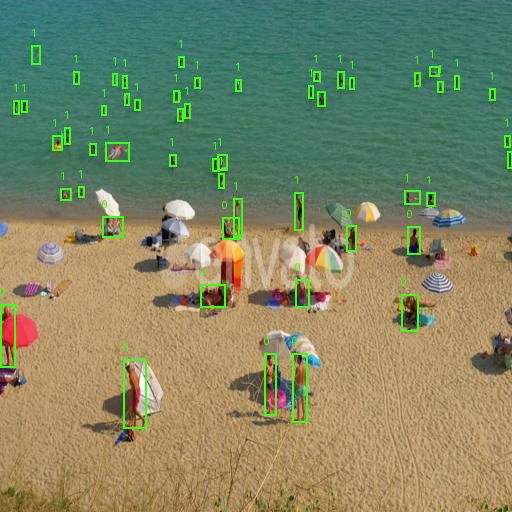

Ground truth: frame_0009_jpg.rf.6e26135c06ee16e5f38c0e2bbe40dba8.jpg


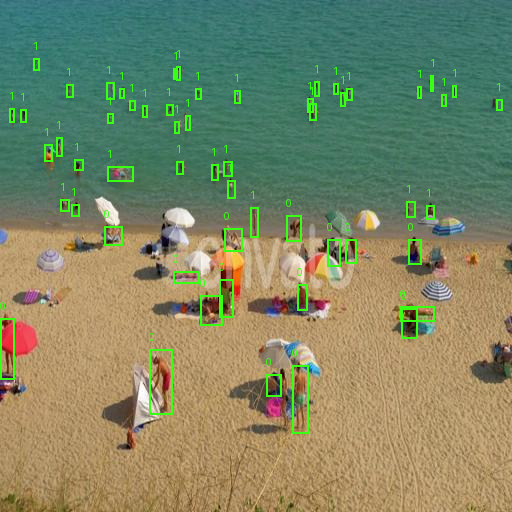

Ground truth: frame_0007_jpg.rf.7af8fede23c4e90999ad4d002781dbee.jpg


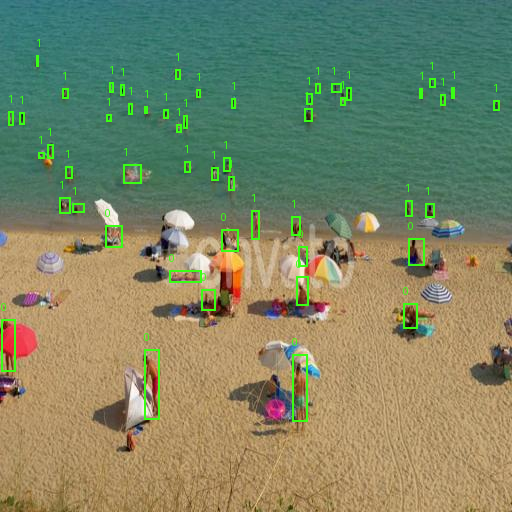

Ground truth: frame_0014_jpg.rf.8455147534f6fe1586d3d7f1ced484e9.jpg


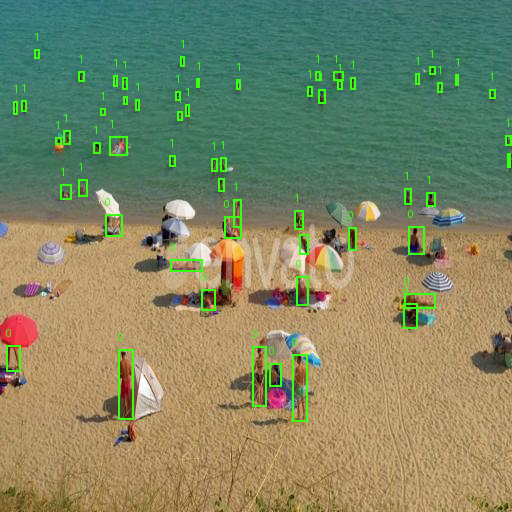

Ground truth: frame_0011_jpg.rf.7f0b5beaed98941a12af1ee18f51be3c.jpg


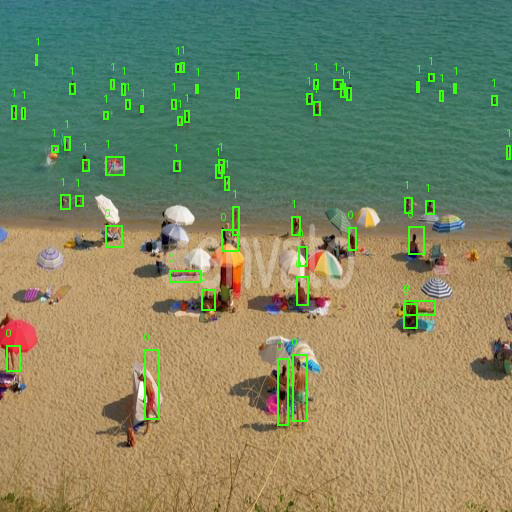

In [32]:

from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
import random

DATA_DIR = Path("/content/VID_DS_BHD-1")
IMG_DIR = DATA_DIR / "train" / "images"
LBL_DIR = DATA_DIR / "train" / "labels"

random.seed(42)

label_files = sorted(LBL_DIR.glob("*.txt"))
random.shuffle(label_files)

shown = 0

for label_file in label_files:
    image_path = next(
        (
            IMG_DIR / f"{label_file.stem}{ext}"
            for ext in [".jpg", ".jpeg", ".png"]
            if (IMG_DIR / f"{label_file.stem}{ext}").exists()
        ),
        None
    )

    if image_path is None:
        continue

    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    W, H = image.size

    for line in label_file.read_text().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue

        class_id = int(float(parts[0]))
        xc, yc, bw, bh = map(float, parts[1:5])

        x1 = int((xc - bw / 2) * W)
        y1 = int((yc - bh / 2) * H)
        x2 = int((xc + bw / 2) * W)
        y2 = int((yc + bh / 2) * H)

        draw.rectangle((x1, y1, x2, y2), outline=(57, 255, 20), width=2)
        draw.text((x1, max(0, y1 - 18)), str(class_id), fill=(57, 255, 20))

    print("Ground truth:", image_path.name)
    display(image)

    shown += 1
    if shown == 5:
        break
